In [1]:
import matplotlib.pyplot as plt
from granad import *
import numpy as np
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Define flake and bulk (Periodic) structure 

# FLAKE
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 
au_s_hoppings = [0.7, -0.875]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)

goldene = (Material("Au")
        .lattice_constant(lattice_constant)
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )
flake = goldene.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)

# BULK
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4
bulk = Periodic(flake, lattice_vectors, fourier_cutoff)

Saving output file as goldene_0.70_-0.88_mu-1.0000_acc0.03_N99.csv
0 of 9801


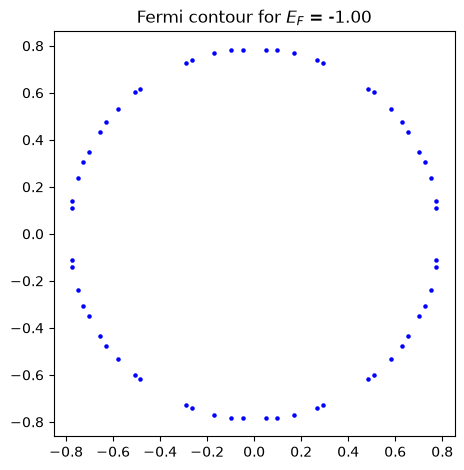

Saving output file as goldene_0.70_-0.88_mu-0.6000_acc0.03_N99.csv
0 of 9801


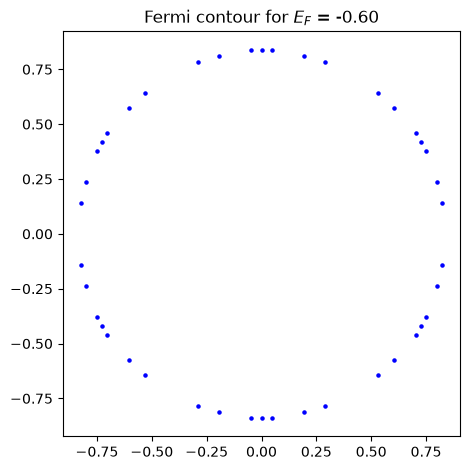

Saving output file as goldene_0.70_-0.88_mu0.0000_acc0.03_N99.csv
0 of 9801


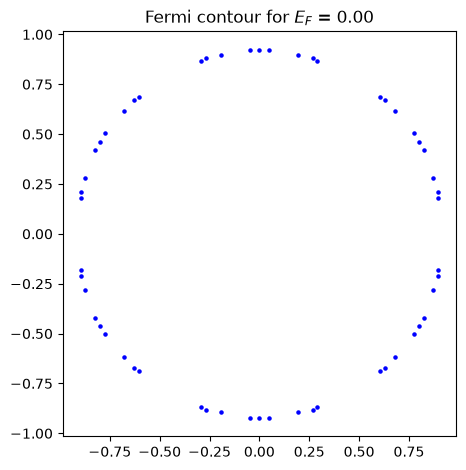

In [3]:
# Define parameters of the k-space sampling and Fermi contour search: 
# Monkhorst-Pack cell size, accuracy for Fermi contour search, Fermi level (mu)
N_monkhorst = 99
accuracy = 3e-2


for mu in [-1, -0.6, 0]:

    # Prepare output filename
    filename = f"goldene_{au_s_hoppings[0]:.2f}_{au_s_hoppings[1]:.2f}_mu{mu:.4f}_acc{accuracy}_N{N_monkhorst}"
    print(f"Saving output file as {filename}.csv")


    # Iterate over points in k-space (Monkhorst-Pack cell) 
    # and check for every point if it corresponds to Fermi energy (mu) within given accuracy

    ks = bulk.get_kgrid_monkhorst_pack([N_monkhorst, N_monkhorst])
    fermi_contour = []
    fermi_energies = []
    energy_band = []
    a1 = lattice_vectors[0]
    a2 = lattice_vectors[1]

    # with open(f"{MY_FILES}/outputs/fermi_contours/{filename}.csv", "w") as output_file:
    for idx, coordinates in enumerate(ks.T):
        if not idx % 10000:
            print(f"{idx} of {len(ks.T)}")
        kx, ky, kz = coordinates
        energy = (2 * au_s_hoppings[1] * (
            np.cos(kx * a1[0] + ky * a1[1]) + 
            np.cos(kx * a2[0] + ky * a2[1]) + 
            np.cos(kx * (a1[0] + a2[0]) + ky * (a1[1] + a2[1]) ) ) )
        if abs(energy - mu) < accuracy:
            fermi_contour.append([float(kx), float(ky), float(kz)])
            fermi_energies.append(energy)
            # output_file.write(f"{float(kx)},{float(ky)},{float(kz)}\n")
        energy_band.append(energy)

    fig, ax = plt.subplots()
    for k_value in fermi_contour:
        ax.scatter(k_value[0], k_value[1], s = 5, color = "blue")
    ax.set_aspect("equal")
    plt.title(f"Fermi contour for $E_F$ = {mu:.2f}")
    plt.tight_layout()
    plt.savefig(f"../../imgs/fermi_contours/fermi_mu_{mu:.2f}.jpg")
    plt.show()

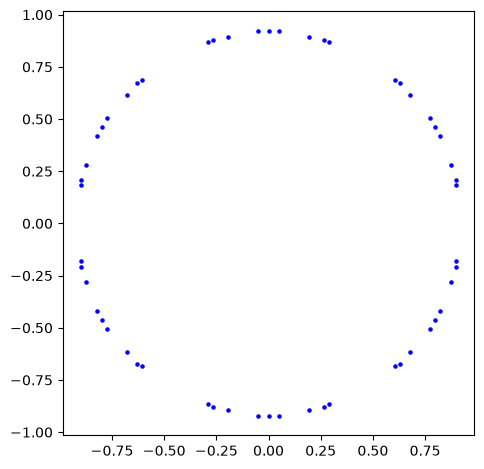

In [4]:
# Plot calculated Fermi contour in 2D

fig, ax = plt.subplots()
for k_value in fermi_contour:
    ax.scatter(k_value[0], k_value[1], s = 5, color = "blue")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(f"../../imgs/fermi_contours/{filename}.jpg")
plt.show()

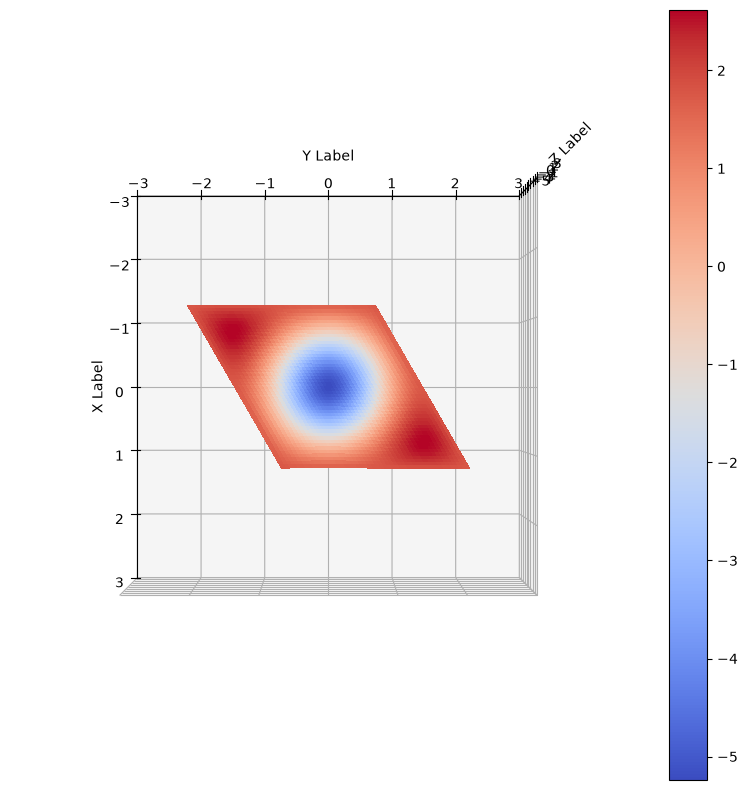

In [5]:
# Visualize 3D energy band structure

energy_band = np.array(energy_band)
energy_band = energy_band.reshape(N_monkhorst,N_monkhorst)

kx_mesh = ks[0].reshape(N_monkhorst,N_monkhorst)
ky_mesh = ks[1].reshape(N_monkhorst,N_monkhorst)

fig = plt.figure(figsize=[10,10])
ax = fig.add_subplot(projection='3d')

plot1 = ax.plot_surface(kx_mesh, ky_mesh, energy_band, cmap=cm.coolwarm, linewidth=3, antialiased=False)
fermi_arr = np.array(fermi_contour)
ax.scatter(fermi_arr[:, 0], fermi_arr[:, 1], len(fermi_arr[:,1])*[2.5], color="black", s=1, label="Fermi contour")

ax.set_xlim3d(-3,3)
ax.set_ylim3d(-3,3)

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

ax.view_init(elev=90, azim=0)
plt.colorbar(plot1)

plt.show()

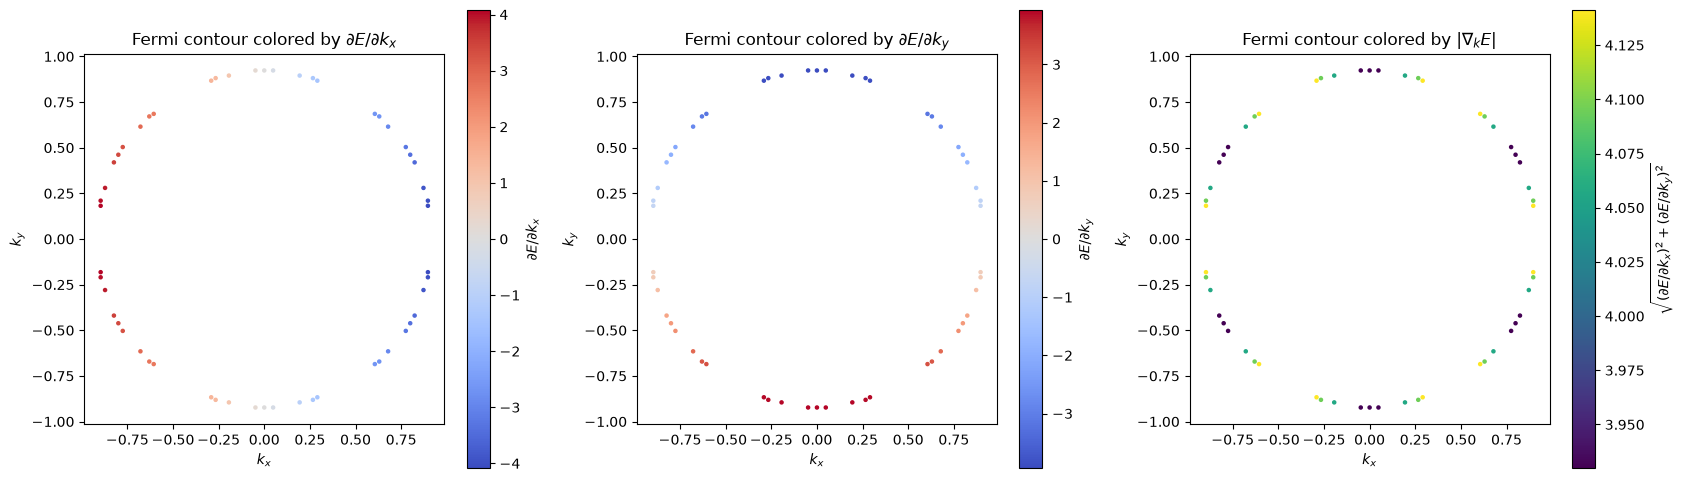

In [6]:
### Analytical derivative for comparison with the velocity operator plot - 
#   based on code from ClauseAI (needs verification)

# Plot Fermi contour colored by dE/dkx and dE/dky (analytical derivatives)

fermi_arr = np.array(fermi_contour)
kx_f = fermi_arr[:, 0]
ky_f = fermi_arr[:, 1]

a1x, a1y = float(a1[0]), float(a1[1])
a2x, a2y = float(a2[0]), float(a2[1])

phase1 = kx_f * a1x + ky_f * a1y
phase2 = kx_f * a2x + ky_f * a2y
phase3 = kx_f * (a1x + a2x) + ky_f * (a1y + a2y)

dE_dkx = (
    -a1x * np.sin(phase1)
    - a2x * np.sin(phase2)
    - (a1x + a2x) * np.sin(phase3)
)

dE_dky = (
    -a1y * np.sin(phase1)
    - a2y * np.sin(phase2)
    - (a1y + a2y) * np.sin(phase3)
)

grad_magnitude = np.sqrt(dE_dkx**2 + dE_dky**2)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, values, label in zip(
    axes[:2],
    [dE_dkx, dE_dky],
    [r"$\partial E / \partial k_x$", r"$\partial E / \partial k_y$"],
):
    sc = ax.scatter(kx_f, ky_f, c=values, cmap="coolwarm", s=5)
    plt.colorbar(sc, ax=ax, label=label)
    ax.set_xlabel(r"$k_x$")
    ax.set_ylabel(r"$k_y$")
    ax.set_title(f"Fermi contour colored by {label}")
    ax.set_aspect("equal")

sc = axes[2].scatter(kx_f, ky_f, c=grad_magnitude, cmap="viridis", s=5)
plt.colorbar(sc, ax=axes[2], label=r"$\sqrt{(\partial E/\partial k_x)^2 + (\partial E/\partial k_y)^2}$")
axes[2].set_xlabel(r"$k_x$")
axes[2].set_ylabel(r"$k_y$")
axes[2].set_title(r"Fermi contour colored by $|\nabla_k E|$")
axes[2].set_aspect("equal")

plt.tight_layout()
plt.show()

